# Proyecto Final de Minería de Datos — Fase de Preparación de Datos (CRISP-DM)
## Dataset: Predicción de Abandono de Clientes de Tarjetas de Crédito (*Credit Card Churn*)

Este notebook desarrolla las fases de **Comprensión de los Datos** y **Preparación de los Datos** siguiendo la metodología **CRISP-DM** y los lineamientos del curso (*sin incluir todavía ingeniería de características como transformaciones o balanceo, los cuales se realizan en el Notebook 02*).

### Contenido del Notebook:
1. **Carga e Integración de Datos**
2. **Reporte Automatizado con Pandas Profiling (`ydata-profiling`)**
3. **Selección Inicial de Variables (Eliminación de Identificadores y Data Leakage)**
4. **Descripción Estadística y Análisis Exploratorio (EDA)**
5. **Verificación de Reglas de Calidad y Limpieza de Atípicos / Errores (Tabla 4 CRISP-DM)**
6. **Limpieza e Imputación de Valores Nulos — Regla del 15% (Tabla 5 CRISP-DM)**
7. **Análisis de Correlaciones para Redundancia (Multicolinealidad)**
8. **Análisis de Correlaciones y Asociación para Irrelevancia (Frente a la Variable Objetivo)**
9. **Exportación del Dataset Limpio para Modelado**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (10, 5)

# Carga del dataset original
df = pd.read_csv("credit_card_churn.csv")
print(f"Dimensiones originales del dataset: {df.shape[0]} filas x {df.shape[1]} columnas\n")
df.info()


Dimensiones originales del dataset: 10127 filas x 23 columnas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender            

In [2]:
# Visualización de los primeros 5 registros
df.head()


CLIENTNUM     Attrition_Flag  Customer_Age Gender  Dependent_count Education_Level Marital_Status Income_Category Card_Category  Months_on_book  Total_Relationship_Count  Months_Inactive_12_mon  Contacts_Count_12_mon  Credit_Limit  Total_Revolving_Bal  Avg_Open_To_Buy  Total_Amt_Chng_Q4_Q1  Total_Trans_Amt  Total_Trans_Ct  Total_Ct_Chng_Q4_Q1  Avg_Utilization_Ratio  Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1  Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0  768805383  Existing Customer            45      M                3     High School        Married     $60K - $80K          Blue              39                         5                       1                      3       12691.0                  777          11914.0                 1.335             1144              42                1.625                  0.0

---
## 2. Reporte Automatizado con Pandas Profiling (`ydata-profiling`)
Se genera el perfilamiento exploratorio completo del dataset original y se exporta al archivo interactivo `reporte_profiling_churn.html`.


In [3]:
from ydata_profiling import ProfileReport

# Excluimos únicamente las 2 columnas con nombres largos residuales de Naive Bayes para el reporte visual
cols_nb = [c for c in df.columns if c.startswith('Naive_Bayes_Classifier')]
profile = ProfileReport(
    df.drop(columns=cols_nb),
    title="Pandas Profiling - Credit Card Churn Dataset",
    explorative=True
)
profile.to_file("reporte_profiling_churn.html")
print("Reporte generado exitosamente en: reporte_profiling_churn.html")


Reporte generado exitosamente en: reporte_profiling_churn.html


---
## 3. Selección Inicial de Variables
Al inspeccionar la estructura del dataset y su diccionario de datos, identificamos **3 variables que deben descartarse de inmediato** antes del análisis:
1. **`CLIENTNUM`**: Número identificador único de cuenta/cliente. No posee significado estadístico ni generalización predictiva.
2. **`Naive_Bayes_Classifier_..._1` y `Naive_Bayes_Classifier_..._2`**: Son probabilidades precalculadas por un clasificador Naive Bayes del autor original del dataset que codifican directamente la variable objetivo (`Attrition_Flag`). Mantenerlas produciría **fuga de datos (*Data Leakage*)** artificial.


In [4]:
cols_drop_init = [
    'CLIENTNUM',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'
]
df_sel = df.drop(columns=cols_drop_init).copy()
print(f"Columnas eliminadas ({len(cols_drop_init)}): {cols_drop_init}")
print(f"Nuevas dimensiones: {df_sel.shape[0]} filas x {df_sel.shape[1]} columnas")
print(f"Registros duplicados exactos encontrados: {df_sel.duplicated().sum()}")


Columnas eliminadas (3): ['CLIENTNUM', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']
Nuevas dimensiones: 10127 filas x 20 columnas
Registros duplicados exactos encontrados: 0


---
## 4. Descripción Estadística y Análisis Exploratorio (EDA)
A continuación, se analizan los estadísticos descriptivos de las **14 variables numéricas** y la distribución de frecuencias de las **6 variables categóricas** (incluyendo la variable objetivo `Attrition_Flag`).


In [5]:
num_cols = df_sel.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_sel.select_dtypes(exclude=[np.number]).columns.tolist()

desc_num = df_sel[num_cols].describe().T
desc_num['skewness'] = df_sel[num_cols].skew()
desc_num['kurtosis'] = df_sel[num_cols].kurt()
print("=== ESTADÍSTICOS DESCRIPTIVOS DE VARIABLES NUMÉRICAS ===")
print(desc_num[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness']].round(2).to_string())


=== ESTADÍSTICOS DESCRIPTIVOS DE VARIABLES NUMÉRICAS ===
                            count     mean      std     min      25%      50%       75%       max  skewness
Customer_Age              10127.0    46.33     8.02    26.0    41.00    46.00     52.00     73.00     -0.03
Dependent_count           10127.0     2.35     1.30     0.0     1.00     2.00      3.00      5.00     -0.02
Months_on_book            10127.0    35.93     7.99    13.0    31.00    36.00     40.00     56.00     -0.11
Total_Relationship_Count  10127.0     3.81     1.55     1.0     3.00     4.00      5.00      6.00     -0.16
Months_Inactive_12_mon    10127.0     2.34     1.01     0.0     2.00     2.00      3.00      6.00      0.63
Contacts_Count_12_mon     10127.0     2.46     1.11     0.0     2.00     2.00      3.00      6.00      0.01
Credit_Limit              10127.0  8631.95  9088.78  1438.3  2555.00  4549.00  11067.50  34516.00      1.67
Total_Revolving_Bal       10127.0  1162.81   814.99     0.0   359.00  1276.00  

=== DISTRIBUCIÓN DE VARIABLES CATEGÓRICAS ===

--- Attrition_Flag ---
                   Frecuencia  Porcentaje (%)
Attrition_Flag                               
Existing Customer        8500           83.93
Attrited Customer        1627           16.07

--- Gender ---
        Frecuencia  Porcentaje (%)
Gender                            
F             5358           52.91
M             4769           47.09

--- Education_Level ---
                 Frecuencia  Porcentaje (%)
Education_Level                            
Graduate               3128           30.89
High School            2013           19.88
Unknown                1519           15.00
Uneducated             1487           14.68
College                1013           10.00
Post-Graduate           516            5.10
Doctorate               451            4.45

--- Marital_Status ---
                Frecuencia  Porcentaje (%)
Marital_Status                            
Married               4687           46.28
Single          

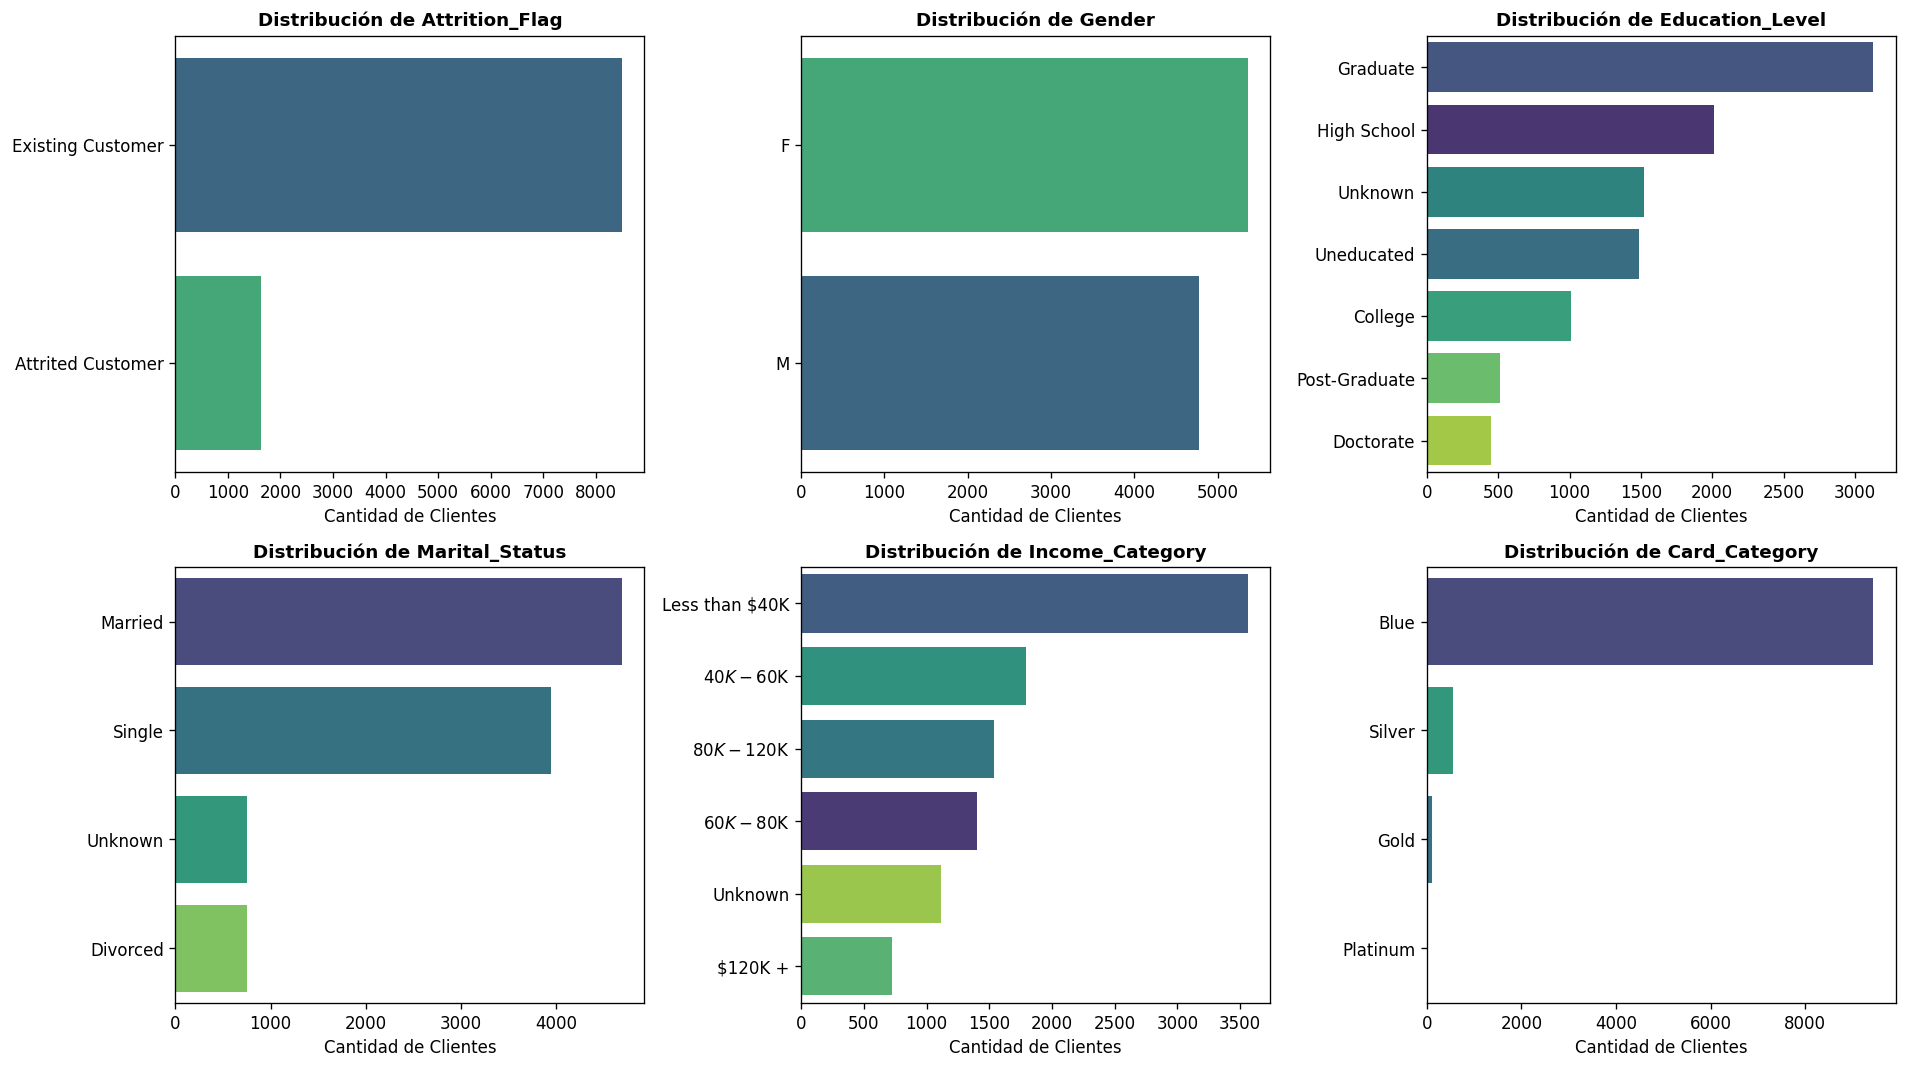

In [6]:
print("=== DISTRIBUCIÓN DE VARIABLES CATEGÓRICAS ===")
for c in cat_cols:
    vc = df_sel[c].value_counts(dropna=False)
    pct = (vc / len(df_sel) * 100).round(2)
    print(f"\n--- {c} ---")
    print(pd.DataFrame({'Frecuencia': vc, 'Porcentaje (%)': pct}))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for idx, c in enumerate(cat_cols):
    order = df_sel[c].value_counts().index
    sns.countplot(data=df_sel, y=c, order=order, ax=axes[idx], palette="viridis", hue=c, legend=False)
    axes[idx].set_title(f"Distribución de {c}", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Cantidad de Clientes")
    axes[idx].set_ylabel("")
plt.tight_layout()
plt.show()


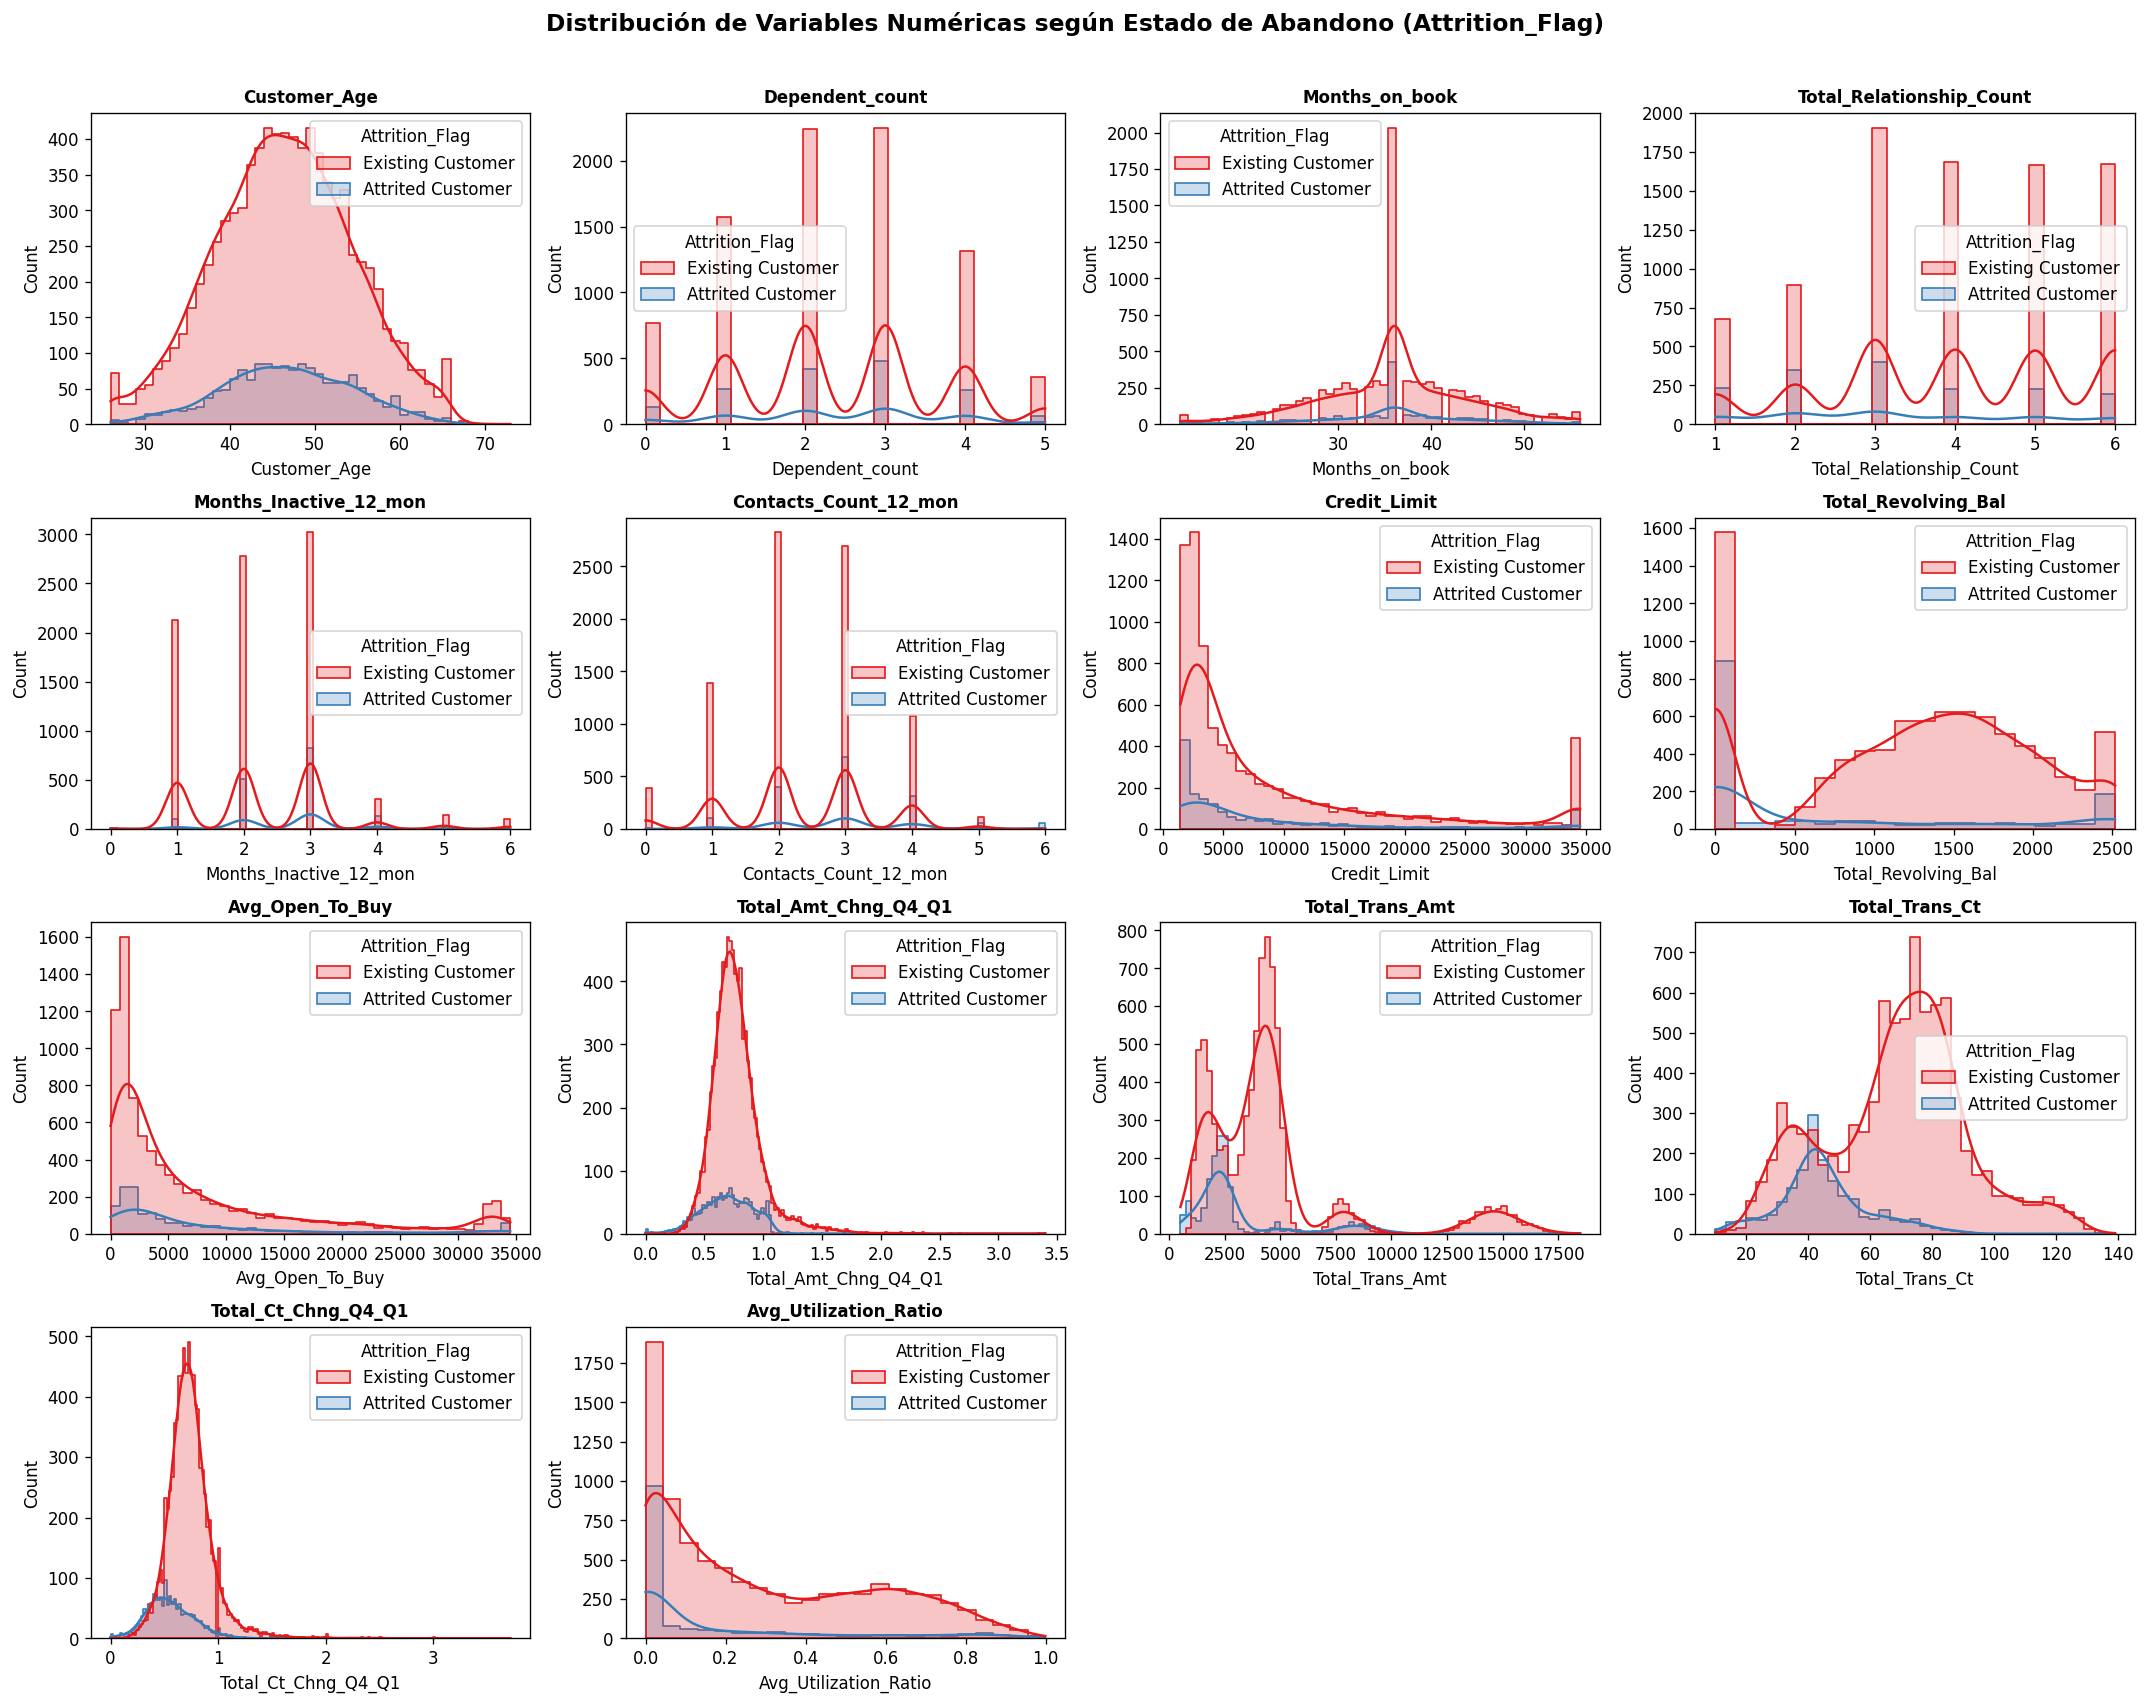

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()
for idx, c in enumerate(num_cols):
    sns.histplot(data=df_sel, x=c, hue='Attrition_Flag', kde=True, ax=axes[idx], palette="Set1", element="step")
    axes[idx].set_title(c, fontsize=10, fontweight='bold')
for idx in range(len(num_cols), len(axes)):
    axes[idx].axis('off')
plt.suptitle("Distribución de Variables Numéricas según Estado de Abandono (Attrition_Flag)", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


---
## 5. Verificación de Reglas de Calidad y Limpieza de Atípicos / Errores (Tabla 4 CRISP-DM)

Se contrastan los valores observados en el dataset frente a las **Reglas de Calidad del Negocio Bancario**:
- **Errores Categóricos (`"Unknown"`)**: Las variables `Education_Level` (1,519 registros), `Income_Category` (1,112 registros) y `Marital_Status` (749 registros) contienen la cadena `"Unknown"`, la cual no corresponde a una categoría válida del dominio de negocio sino a **valores faltantes (nulos) codificados como texto**. Por tanto, se transforman a `np.nan` para ser procesados bajo el protocolo formal de limpieza de nulos.
- **Rangos de Negocio en Variables Numéricas**: Todas las variables numéricas se encuentran dentro de rangos lógicos y físicamente posibles (`Customer_Age` entre 26 y 73 años, `Avg_Utilization_Ratio` entre 0.0 y 1.0, saldos y montos positivos).
- **Atípicos Estadísticos (Criterio IQR)**: Se inspeccionan mediante diagramas de caja (*Boxplots*). Los valores extremos en `Credit_Limit`, `Total_Trans_Amt`, `Total_Amt_Chng_Q4_Q1` y `Total_Ct_Chng_Q4_Q1` corresponden a clientes de tarjetas *Silver/Gold/Platinum* o con picos de consumo real. Para evitar que valores extremos distorsionen modelos sensibles a escala sin perder registros valiosos, se documentan sus umbrales IQR.


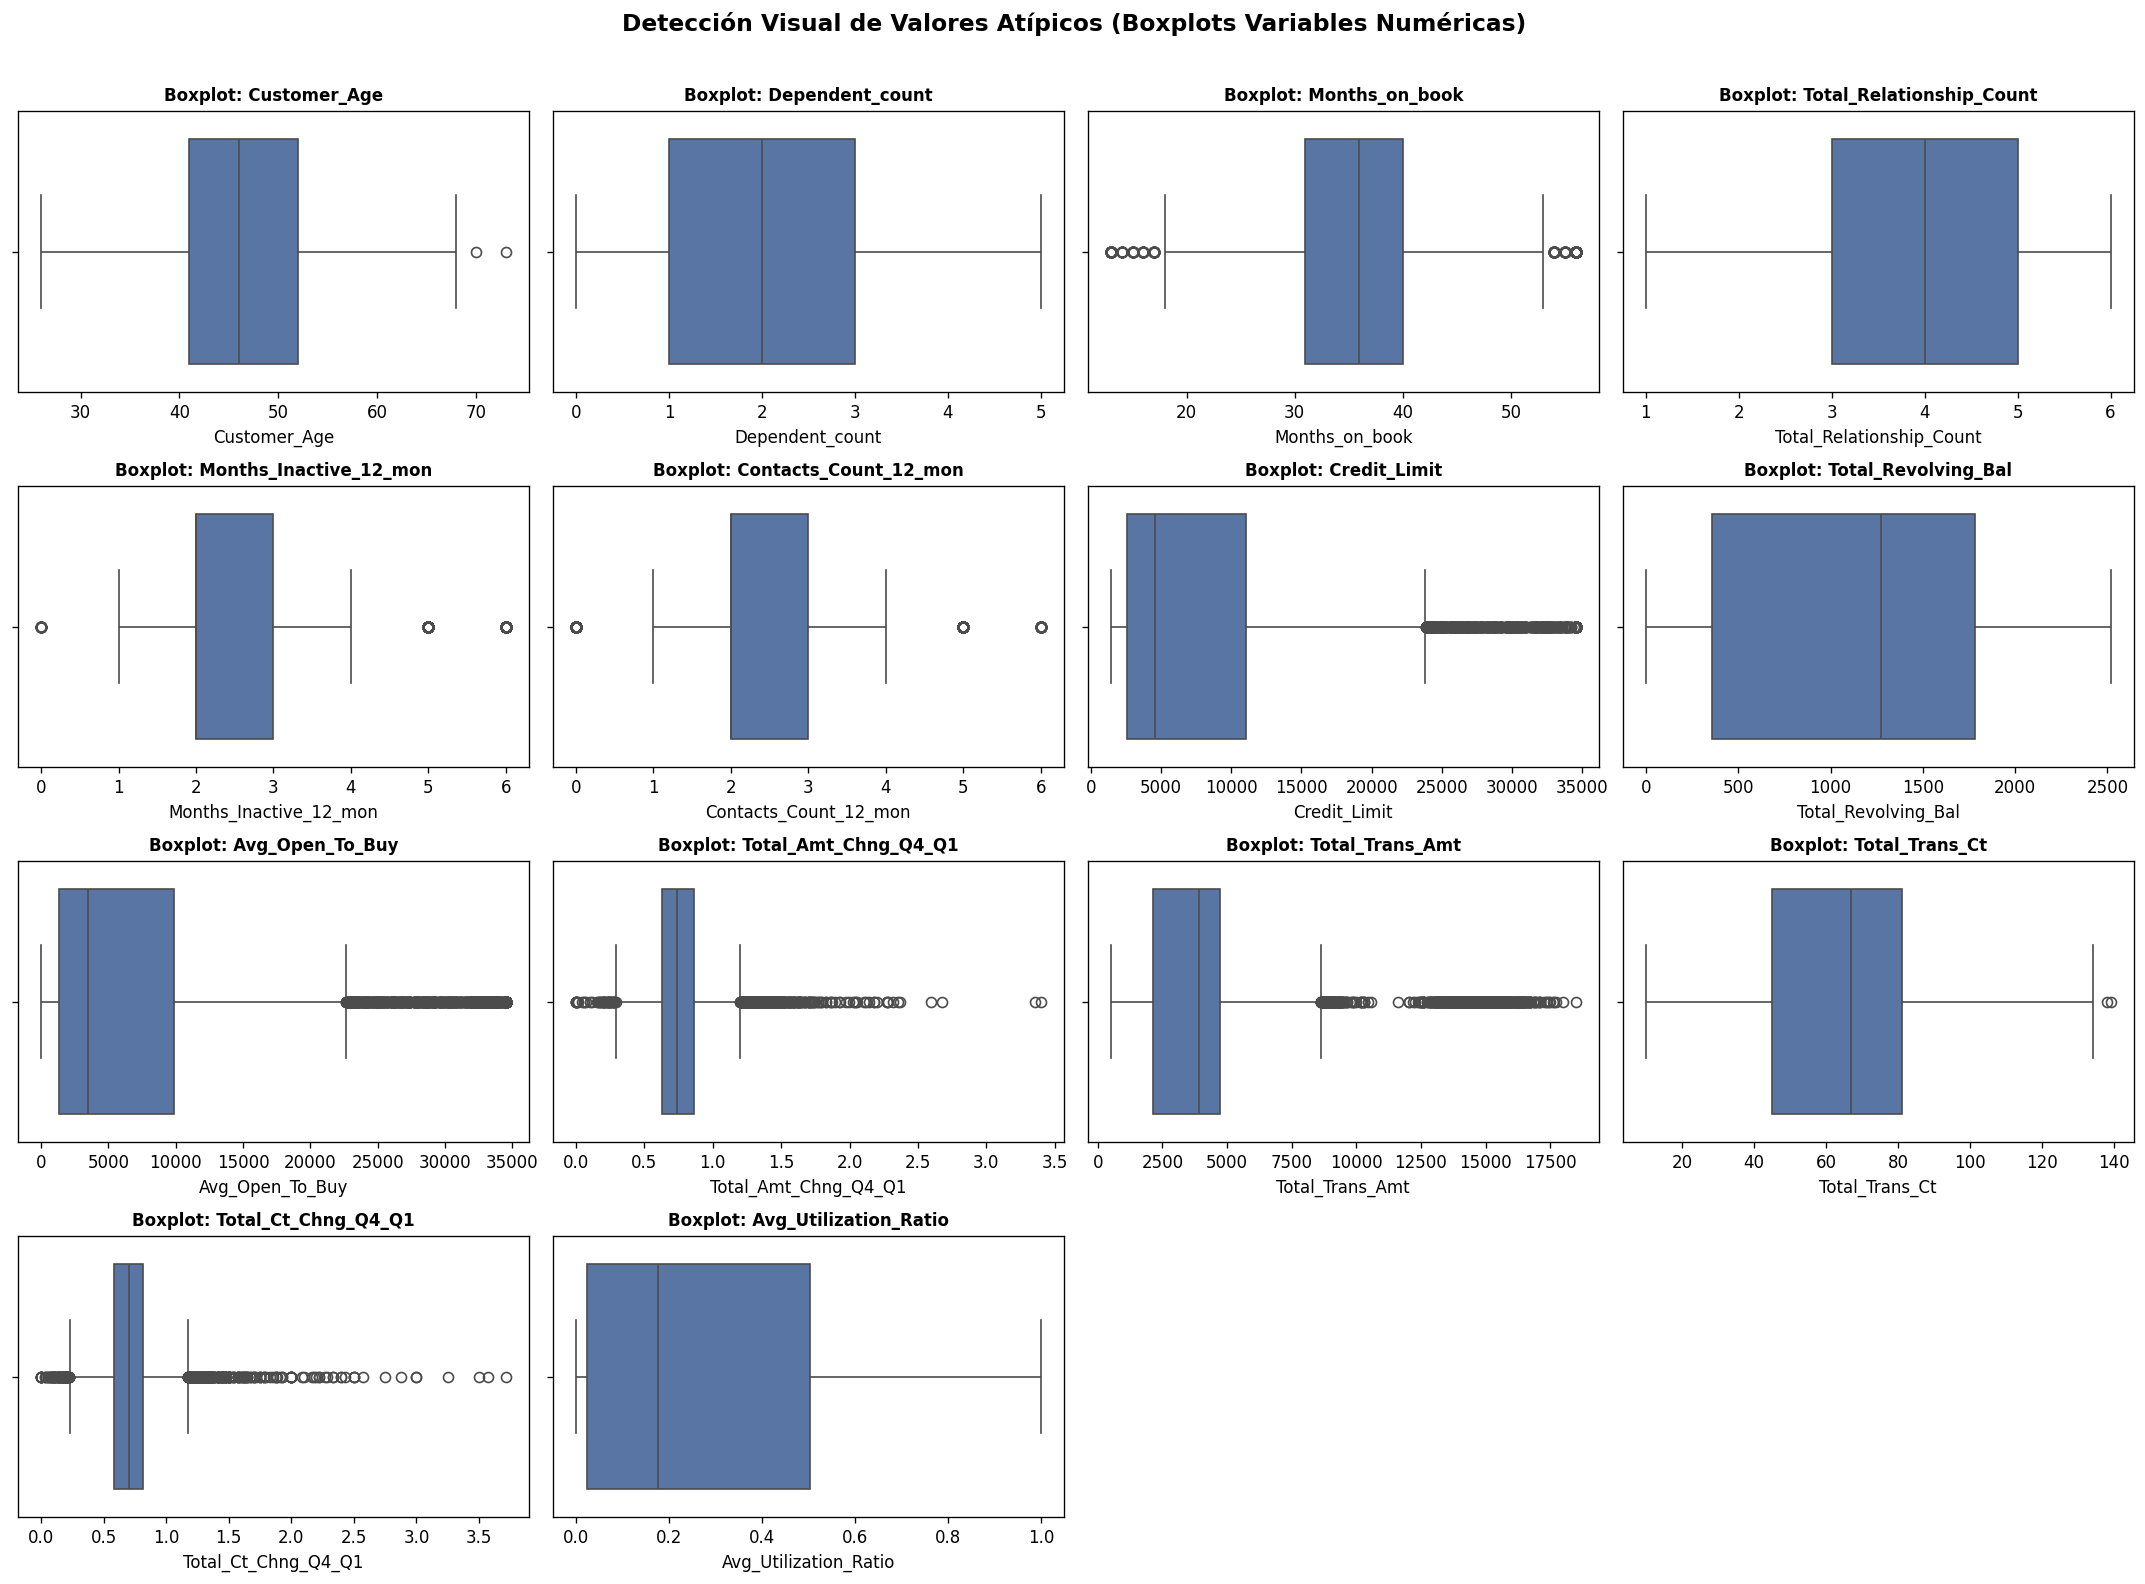

Verificación de tabla de reglas de calidad (Tabla 4 CRISP-DM):
                Variable                                                     Regla de calidad           Mínimo-Máximo / Categorías                        Indicativo de error
          Attrition_Flag                                 Existing Customer, Attrited Customer Existing Customer, Attrited Customer                                  Sin error
            Customer_Age                                                        18 - 100 años                              26 - 73            Sin error (2 atípicos IQR > 70)
                  Gender                                                                 F, M                                 F, M                                  Sin error
         Dependent_count                                                  0 - 10 dependientes                                0 - 5                                  Sin error
         Education_Level Uneducated, High School, College, Graduate

In [8]:
# Visualización de Boxplots para todas las variables numéricas
fig, axes = plt.subplots(4, 4, figsize=(18, 13))
axes = axes.flatten()
for idx, c in enumerate(num_cols):
    sns.boxplot(data=df_sel, x=c, ax=axes[idx], color="#4C72B0")
    axes[idx].set_title(f"Boxplot: {c}", fontsize=10, fontweight='bold')
for idx in range(len(num_cols), len(axes)):
    axes[idx].axis('off')
plt.suptitle("Detección Visual de Valores Atípicos (Boxplots Variables Numéricas)", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Conversión de la categoría anómala 'Unknown' a np.nan para tratamiento formal de nulos
df_nulls = df_sel.replace("Unknown", np.nan).copy()
print("Verificación de tabla de reglas de calidad (Tabla 4 CRISP-DM):")
print(df_tabla4.to_string(index=False))


---
## 6. Limpieza de Nulos — Estrategia del 15% (Tabla 5 CRISP-DM)

Siguiendo estrictamente la regla definida en la metodología:
1. **Eliminar los registros (filas) con más del 15% de valores faltantes**:
   - Evaluando sobre las 19 variables predictoras del cliente, aquellos registros que presentan las 3 variables (`Education_Level`, `Marital_Status`, `Income_Category`) simultáneamente en nulo tienen $3 / 19 = 15.79\% > 15\%$ de valores faltantes. Se identifican **7 registros** en esta condición y se eliminan.
2. **Eliminar las variables (columnas) con más del 15% de valores faltantes**:
   - `Education_Level`: $14.9995\%$ ($\le 15\%$)
   - `Income_Category`: $10.9805\%$ ($\le 15\%$)
   - `Marital_Status`: $7.3961\%$ ($\le 15\%$)
   - Ninguna variable supera el umbral del 15%, por lo que no se elimina ninguna columna por nulos.
3. **Imputar variables con máximo 15% de valores faltantes**:
   - Al ser las 3 variables de naturaleza **categórica**, se imputan utilizando la **moda** de cada variable:
     - `Education_Level` $\rightarrow$ Imputada con la moda `"Graduate"`.
     - `Income_Category` $\rightarrow$ Imputada con la moda `"Less than $40K"`.
     - `Marital_Status` $\rightarrow$ Imputada con la moda `"Married"`.


In [9]:
# 1. Porcentaje de nulos por columna
null_col_pct = (df_nulls.isnull().sum() / len(df_nulls) * 100).round(4)
null_summary = pd.DataFrame({
    'Nulos Totales': df_nulls.isnull().sum(),
    'Porcentaje (%)': null_col_pct
})
print("=== CONTEO Y PORCENTAJE DE NULOS POR VARIABLE (ANTES DE IMPUTAR) ===")
print(null_summary[null_summary['Nulos Totales'] > 0])

# 2. Eliminar registros con más del 15% de valores faltantes (sobre las 19 variables predictoras)
pred_cols = [c for c in df_nulls.columns if c != 'Attrition_Flag']
row_null_pct = (df_nulls[pred_cols].isnull().sum(axis=1) / len(pred_cols)) * 100
rows_over_15 = (row_null_pct > 15.0).sum()
print(f"\nRegistros con > 15% de valores faltantes (3/19 = 15.79%): {rows_over_15} registros eliminados.")

df_clean = df_nulls.loc[row_null_pct <= 15.0].copy()
print(f"Dimensiones tras eliminar registros > 15% nulos: {df_clean.shape[0]} filas x {df_clean.shape[1]} columnas")

# 3. Imputar variables con <= 15% de nulos usando la moda (variables categóricas)
print("\n=== ACCIONES REALIZADAS (TABLA 5 CRISP-DM) ===")
for col in ['Education_Level', 'Income_Category', 'Marital_Status']:
    mode_val = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(mode_val)
    print(f"- {col}: Imputada por la moda '{mode_val}'")

print(f"\nTotal de valores nulos restantes en el dataset: {df_clean.isnull().sum().sum()}")


=== CONTEO Y PORCENTAJE DE NULOS POR VARIABLE (ANTES DE IMPUTAR) ===
                 Nulos Totales  Porcentaje (%)
Education_Level           1519         14.9995
Marital_Status             749          7.3961
Income_Category           1112         10.9805

Registros con > 15% de valores faltantes (3/19 = 15.79%): 7 registros eliminados.
Dimensiones tras eliminar registros > 15% nulos: 10120 filas x 20 columnas

=== ACCIONES REALIZADAS (TABLA 5 CRISP-DM) ===
- Education_Level (15.00% nulos): Imputada por la moda 'Graduate'
- Income_Category (10.98% nulos): Imputada por la moda 'Less than $40K'
- Marital_Status  (7.40% nulos) : Imputada por la moda 'Married'

Total de valores nulos restantes en el dataset: 0


---
## 7. Análisis de Correlaciones para Redundancia (Multicolinealidad)

Se calcula la matriz de correlación de Pearson entre las 14 variables numéricas para identificar variables altamente colineales ($|r| > 0.85$) que aporten información redundante:
- **`Credit_Limit` vs `Avg_Open_To_Buy`**: Presentan una correlación lineal de **$r = 0.9960$** (prácticamente 1.0), debido a que contablemente `Avg_Open_To_Buy = Credit_Limit - Total_Revolving_Bal`. Por consiguiente, **se elimina la variable `Avg_Open_To_Buy` por redundancia perfecta**.
- **`Customer_Age` vs `Months_on_book`** ($r = 0.7889$) y **`Total_Trans_Amt` vs `Total_Trans_Ct`** ($r = 0.8072$): Presentan correlación moderada-alta pero inferior al umbral crítico de 0.85 y capturan dimensiones distintas del comportamiento del cliente (edad biológica vs antigüedad; volumen monetario vs frecuencia transaccional), por lo que se conservan.


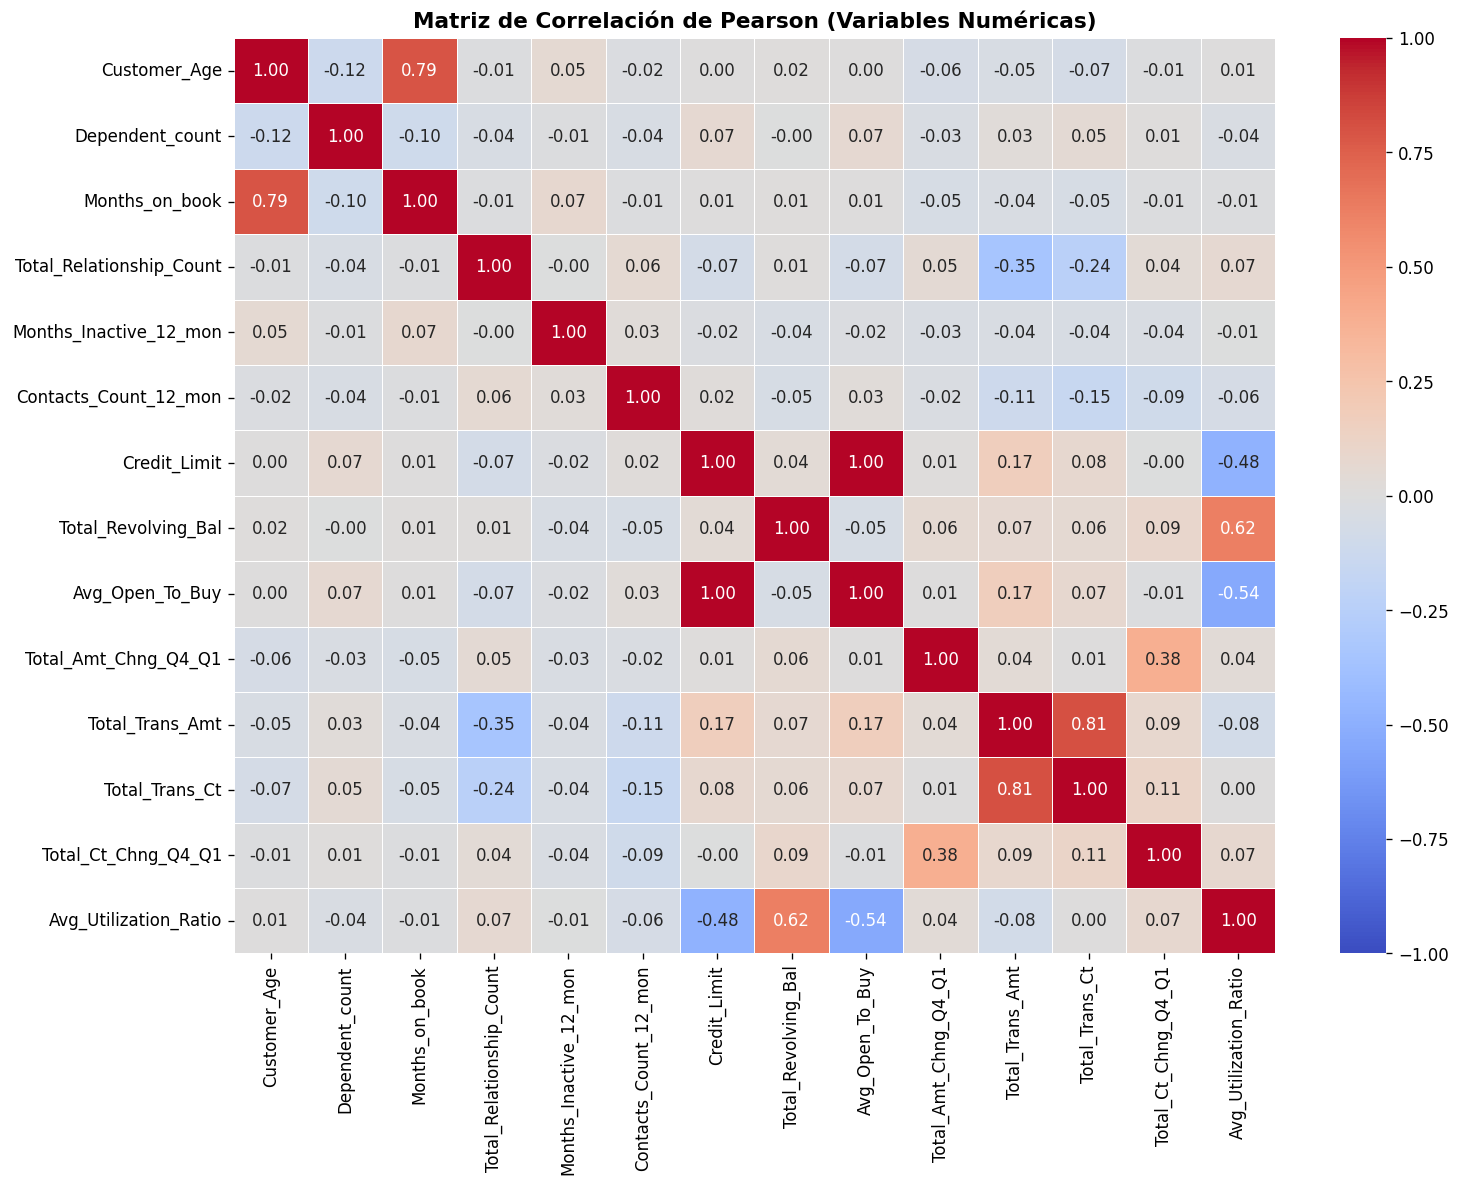

Pares de variables con correlación |r| > 0.60:
- Credit_Limit <-> Avg_Open_To_Buy: r = 0.9960 (REDUNDANTE -> Se elimina Avg_Open_To_Buy)
- Total_Trans_Amt <-> Total_Trans_Ct: r = 0.8072 (Se conservan ambas)
- Customer_Age <-> Months_on_book: r = 0.7889 (Se conservan ambas)
- Total_Revolving_Bal <-> Avg_Utilization_Ratio: r = 0.6240 (Se conservan ambas)

Dimensiones tras eliminar variable redundante ('Avg_Open_To_Buy'): 10120 filas x 19 columnas


In [10]:
corr_matrix = df_clean[num_cols].corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de Correlación de Pearson (Variables Numéricas)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Eliminación de variable redundante Avg_Open_To_Buy (r = 0.9960 con Credit_Limit)
df_clean_nored = df_clean.drop(columns=['Avg_Open_To_Buy']).copy()
print("Variable eliminada por redundancia: 'Avg_Open_To_Buy' (r = 0.9960 con 'Credit_Limit')")
print(f"Dimensiones actualizadas: {df_clean_nored.shape[0]} filas x {df_clean_nored.shape[1]} columnas")


---
## 8. Análisis de Correlaciones para Irrelevancia (Frente a la Variable Objetivo `Attrition_Flag`)

Para evaluar la relevancia predictiva de cada variable con respecto al abandono (`Attrition_Flag`: `Attrited Customer` = 1, `Existing Customer` = 0):
1. **Variables Numéricas**: Se calcula la correlación Punto-Biserial ($r_{pb}$) y el estadístico $F$ de ANOVA unidireccional (con su $p$-valor).
2. **Variables Categóricas**: Se aplica la prueba de independencia **Chi-Cuadrado ($\chi^2$)** y el coeficiente **V de Cramér**.


=== RELEVANCIA DE VARIABLES NUMÉRICAS FRENTE A ATTRITION_FLAG ===
       Variable Numérica    r_pb  |r_pb|  ANOVA F     p-valor            Diagnóstico
          Total_Trans_Ct -0.3714  0.3714  1619.22  0.0000e+00   Relevante (p < 0.05)
     Total_Ct_Chng_Q4_Q1 -0.2899  0.2899   928.61 3.2735e-195   Relevante (p < 0.05)
     Total_Revolving_Bal -0.2636  0.2636   755.78 1.5973e-160   Relevante (p < 0.05)
   Contacts_Count_12_mon  0.2046  0.2046   442.20  4.0112e-96   Relevante (p < 0.05)
   Avg_Utilization_Ratio -0.1788  0.1788   334.29  1.6918e-73   Relevante (p < 0.05)
         Total_Trans_Amt -0.1685  0.1685   295.82  2.2666e-65   Relevante (p < 0.05)
  Months_Inactive_12_mon  0.1523  0.1523   240.41  1.3223e-53   Relevante (p < 0.05)
Total_Relationship_Count -0.1498  0.1498   232.28  7.1334e-52   Relevante (p < 0.05)
    Total_Amt_Chng_Q4_Q1 -0.1308  0.1308   176.24  6.9247e-40   Relevante (p < 0.05)
            Credit_Limit -0.0238  0.0238     5.72  1.6785e-02   Relevante (p < 0.05)

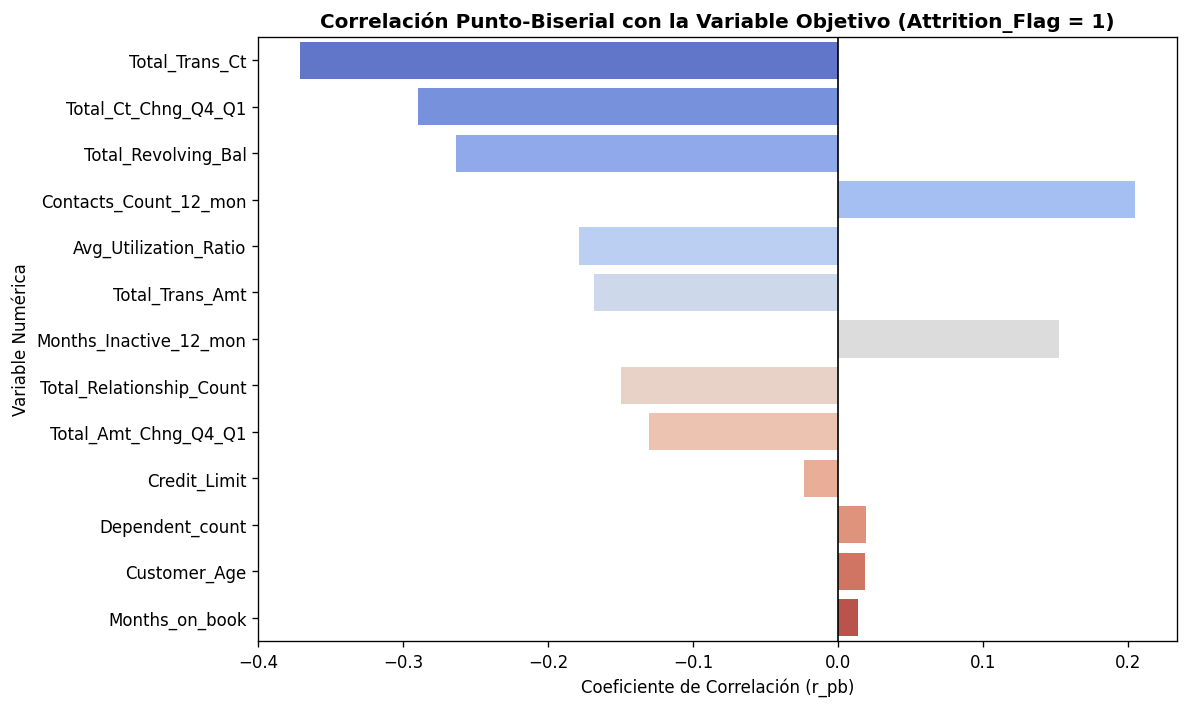

In [11]:
y_bin = (df_clean_nored['Attrition_Flag'] == 'Attrited Customer').astype(int)
num_cols_rem = [c for c in num_cols if c != 'Avg_Open_To_Buy']
cat_cols_rem = [c for c in cat_cols if c != 'Attrition_Flag']

# 1. Correlación Punto-Biserial y ANOVA F para variables numéricas
num_rel_rows = []
for c in num_cols_rem:
    r_pb, p_val = stats.pointbiserialr(df_clean_nored[c], y_bin)
    f_stat, _ = stats.f_oneway(df_clean_nored.loc[y_bin == 0, c], df_clean_nored.loc[y_bin == 1, c])
    num_rel_rows.append((c, round(r_pb, 4), round(abs(r_pb), 4), round(f_stat, 2), f"{p_val:.4e}"))

df_num_rel = pd.DataFrame(num_rel_rows, columns=["Variable Numérica", "r_pb", "|r_pb|", "ANOVA F", "p-valor"]).sort_values(by="|r_pb|", ascending=False)
print("=== RELEVANCIA DE VARIABLES NUMÉRICAS FRENTE A ATTRITION_FLAG ===")
print(df_num_rel.to_string(index=False))

# 2. Chi-Cuadrado y V de Cramér para variables categóricas
cat_rel_rows = []
for c in cat_cols_rem:
    ct = pd.crosstab(df_clean_nored[c], y_bin)
    chi2, p_val, _, _ = stats.chi2_contingency(ct)
    n = ct.sum().sum()
    cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    cat_rel_rows.append((c, round(chi2, 2), round(cramers_v, 4), f"{p_val:.4e}"))

df_cat_rel = pd.DataFrame(cat_rel_rows, columns=["Variable Categórica", "Chi2", "V de Cramér", "p-valor"]).sort_values(by="V de Cramér", ascending=False)
print("\n=== RELEVANCIA DE VARIABLES CATEGÓRICAS FRENTE A ATTRITION_FLAG (CHI-CUADRADO) ===")
print(df_cat_rel.to_string(index=False))

plt.figure(figsize=(10, 6))
sns.barplot(data=df_num_rel, x="r_pb", y="Variable Numérica", palette="coolwarm", hue="Variable Numérica", legend=False)
plt.axvline(0, color='black', linewidth=1)
plt.title("Correlación Punto-Biserial con la Variable Objetivo (Attrition_Flag = 1)", fontsize=12, fontweight='bold')
plt.xlabel("Coeficiente de Correlación (r_pb)")
plt.tight_layout()
plt.show()


---
## 9. Exportación del Dataset Preparado y Limpio
Se guarda el dataset depurado en `credit_card_churn_limpio.csv` (**10,120 registros y 19 columnas**: 18 variables predictoras + 1 variable objetivo `Attrition_Flag`), listo para la fase de **Ingeniería de Características y Modelado Predictivo Avanzado** en el Notebook 02.


In [12]:
df_clean_nored.to_csv("credit_card_churn_limpio.csv", index=False)
print(f"Archivo guardado exitosamente: credit_card_churn_limpio.csv")
print(f"Dimensiones finales: {df_clean_nored.shape[0]} filas x {df_clean_nored.shape[1]} columnas")
print(f"Columnas finales ({len(df_clean_nored.columns)}): {list(df_clean_nored.columns)}")
print("\nDistribución de la variable objetivo en el dataset limpio:")
print(df_clean_nored['Attrition_Flag'].value_counts())


Archivo guardado exitosamente: credit_card_churn_limpio.csv
Dimensiones finales: 10120 filas x 19 columnas
Columnas finales (19): ['Attrition_Flag', 'Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']

Distribución de la variable objetivo en el dataset limpio:
Attrition_Flag
Existing Customer    8494
Attrited Customer    1626
